In [23]:
from matplotlib import pyplot as plt
import cv2
import numpy as np
import alc

filepath_base = '../template-alumnos/calib/coplanar'

In [24]:
# Tablero 
#    360mmx240mm
#    12x8 Cuadrados, 11x7 Esquinas internas
#    Cada cuadrado mide 30x30
#    las esquinas internas tienen coordenadas (30 i, 30 j) mm, con i = 0, . . . , 10 y j = 0, . . . , 6
#
#    ¿Qué rango debe tener Q ∈ R^{2n×9} para asegurar una solución única de H a menos de un factor de escala?
#               Qh = 0   con h no nulo  =>  rango(Q) debe ser 8
#    Cada punto aporta 2 filas de Q:
#
#       [[P_i.T, 0.T  , -u_i P_i.T],
#        [0.T  , P_i.T, -v_i P_i.T]]
#
#    => Se necesitan al menos 4 puntos para asegurar la solución. 

# U, V coord del tablero real en mm
P_0 = (0,0)
P_1 = (30*10, 0)
P_2 = (0, 30*6)
P_3 = (30*10, 30*6)


In [25]:
num_vistas = 10

# las 4 esquinas internas extremas del tablero en mm, (U, V) con W = 0. Son las mismas para todas las vistas
objPts = np.array([P_0, P_1, P_2, P_3])

# imgPtsList[k-1]: coords en px de la vista k (Im_R_{k}.png)
imgPtsList = [None for _ in range(num_vistas)]

In [26]:
def grilla(rgb):
    """Dibuja líneas auxiliarespara leer coordenadas."""
    h, w = rgb.shape[:2]
    step = 50
    for x in range(0, w, step):
        plt.plot([x, x], [0, h-1], 'y-', linewidth=0.6)
    for y in range(0, h, step):
        plt.plot([0, w-1], [y, y], 'y-', linewidth=0.6)

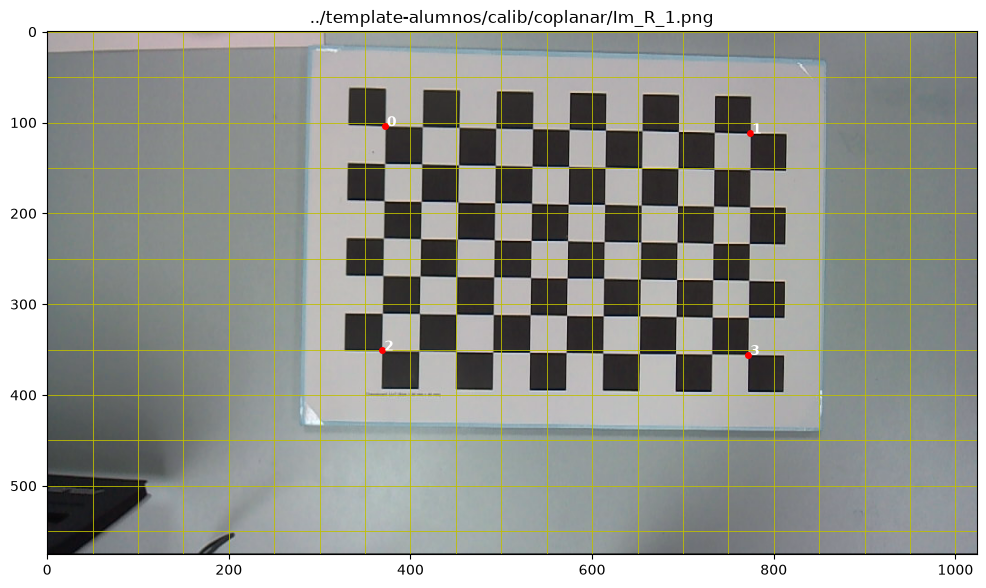

In [27]:
k = 1 # La vista k

filename = f'{filepath_base}/Im_R_{k}.png'
rgb = cv2.imread(filename)

plt.figure(figsize=(12,8), dpi=100)
plt.imshow(rgb)
grilla(rgb)
plt.title(filename)

esq_sup_izq = (372,104)
esq_sup_der = (774,112)
esq_inf_izq = (369,351)
esq_inf_der = (772,356)

plt.plot(esq_sup_izq[0], esq_sup_izq[1],'ro', markersize=4)
plt.plot(esq_sup_der[0], esq_sup_der[1],'ro', markersize=4)  
plt.plot(esq_inf_izq[0], esq_inf_izq[1],'ro', markersize=4)  
plt.plot(esq_inf_der[0], esq_inf_der[1],'ro', markersize=4)  


# (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
plt.text(esq_sup_izq[0] + 2, esq_sup_izq[1], str(0), color='white', fontsize=10, weight='bold')
plt.text(esq_sup_der[0] + 2, esq_sup_der[1], str(1), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_izq[0] + 2, esq_inf_izq[1], str(2), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_der[0] + 2, esq_inf_der[1], str(3), color='white', fontsize=10, weight='bold')

plt.show()

# [*esq_sup_izq, *esq_sup_der] -> aplana las tuplas para tener [u0, v0, u1, v1] en lugar de [(u0,v0), (u1,v1)]
imgPtsList[k-1] = np.array([*esq_sup_izq, *esq_sup_der, *esq_inf_izq, *esq_inf_der])

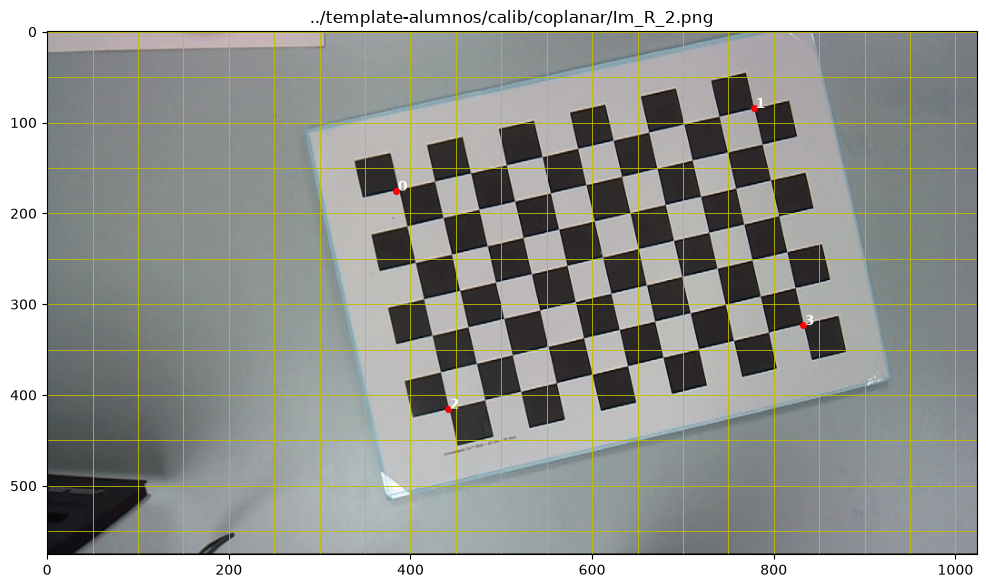

In [28]:
k = 2 # La vista k

filename = f'{filepath_base}/Im_R_{k}.png'
rgb = cv2.imread(filename)

plt.figure(figsize=(12,8), dpi=100)
plt.imshow(rgb)
grilla(rgb)
plt.title(filename)

esq_sup_izq = (384,175)
esq_sup_der = (778,84)
esq_inf_izq = (441,415)
esq_inf_der = (832,323)

plt.plot(esq_sup_izq[0], esq_sup_izq[1],'ro', markersize=4)
plt.plot(esq_sup_der[0], esq_sup_der[1],'ro', markersize=4)  
plt.plot(esq_inf_izq[0], esq_inf_izq[1],'ro', markersize=4)  
plt.plot(esq_inf_der[0], esq_inf_der[1],'ro', markersize=4)  


# (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
plt.text(esq_sup_izq[0] + 2, esq_sup_izq[1], str(0), color='white', fontsize=10, weight='bold')
plt.text(esq_sup_der[0] + 2, esq_sup_der[1], str(1), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_izq[0] + 2, esq_inf_izq[1], str(2), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_der[0] + 2, esq_inf_der[1], str(3), color='white', fontsize=10, weight='bold')

plt.show()

# [*esq_sup_izq, *esq_sup_der] -> aplana las tuplas para tener [u0, v0, u1, v1] en lugar de [(u0,v0), (u1,v1)]
imgPtsList[k-1] = np.array([*esq_sup_izq, *esq_sup_der, *esq_inf_izq, *esq_inf_der])

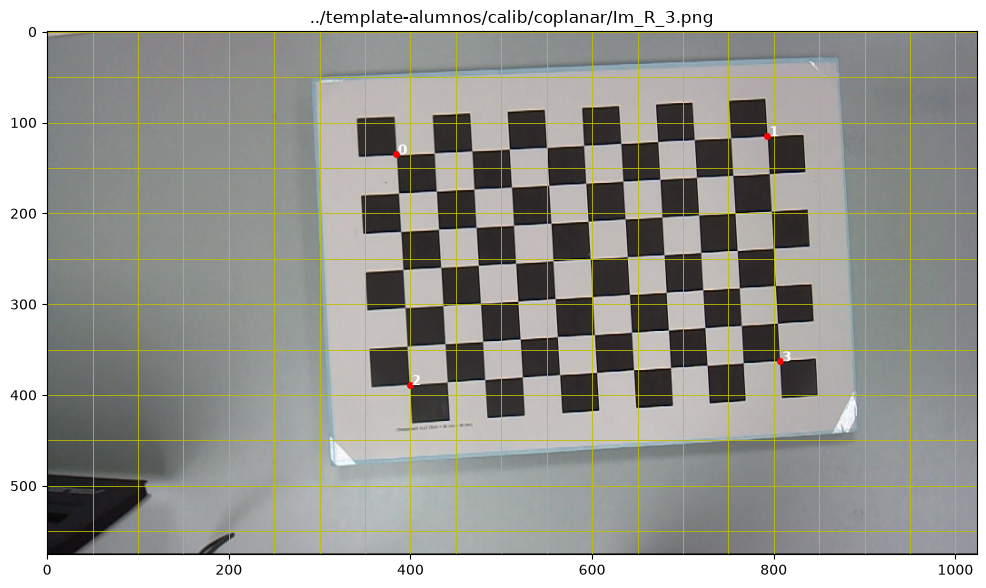

In [29]:
k = 3 # La vista k

filename = f'{filepath_base}/Im_R_{k}.png'
rgb = cv2.imread(filename)

plt.figure(figsize=(12,8), dpi=100)
plt.imshow(rgb)
grilla(rgb)
plt.title(filename)

esq_sup_izq = (384,135)
esq_sup_der = (793,115)
esq_inf_izq = (399,389)
esq_inf_der = (807,363)

plt.plot(esq_sup_izq[0], esq_sup_izq[1],'ro', markersize=4)
plt.plot(esq_sup_der[0], esq_sup_der[1],'ro', markersize=4)  
plt.plot(esq_inf_izq[0], esq_inf_izq[1],'ro', markersize=4)  
plt.plot(esq_inf_der[0], esq_inf_der[1],'ro', markersize=4)  


# (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
plt.text(esq_sup_izq[0] + 2, esq_sup_izq[1], str(0), color='white', fontsize=10, weight='bold')
plt.text(esq_sup_der[0] + 2, esq_sup_der[1], str(1), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_izq[0] + 2, esq_inf_izq[1], str(2), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_der[0] + 2, esq_inf_der[1], str(3), color='white', fontsize=10, weight='bold')

plt.show()

# [*esq_sup_izq, *esq_sup_der] -> aplana las tuplas para tener [u0, v0, u1, v1] en lugar de [(u0,v0), (u1,v1)]
imgPtsList[k-1] = np.array([*esq_sup_izq, *esq_sup_der, *esq_inf_izq, *esq_inf_der])

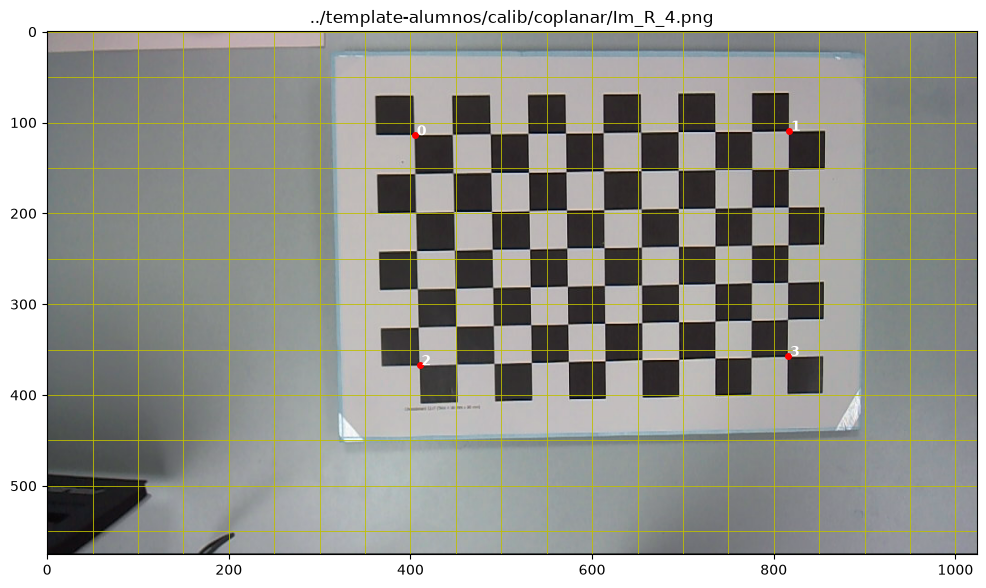

In [30]:
k = 4 # La vista k

filename = f'{filepath_base}/Im_R_{k}.png'
rgb = cv2.imread(filename)

plt.figure(figsize=(12,8), dpi=100)
plt.imshow(rgb)
grilla(rgb)
plt.title(filename)

esq_sup_izq = (405,114)
esq_sup_der = (817,109)
esq_inf_izq = (410,367)
esq_inf_der = (816,357)

plt.plot(esq_sup_izq[0], esq_sup_izq[1],'ro', markersize=4)
plt.plot(esq_sup_der[0], esq_sup_der[1],'ro', markersize=4)  
plt.plot(esq_inf_izq[0], esq_inf_izq[1],'ro', markersize=4)  
plt.plot(esq_inf_der[0], esq_inf_der[1],'ro', markersize=4)  


# (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
plt.text(esq_sup_izq[0] + 2, esq_sup_izq[1], str(0), color='white', fontsize=10, weight='bold')
plt.text(esq_sup_der[0] + 2, esq_sup_der[1], str(1), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_izq[0] + 2, esq_inf_izq[1], str(2), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_der[0] + 2, esq_inf_der[1], str(3), color='white', fontsize=10, weight='bold')

plt.show()

# [*esq_sup_izq, *esq_sup_der] -> aplana las tuplas para tener [u0, v0, u1, v1] en lugar de [(u0,v0), (u1,v1)]
imgPtsList[k-1] = np.array([*esq_sup_izq, *esq_sup_der, *esq_inf_izq, *esq_inf_der])

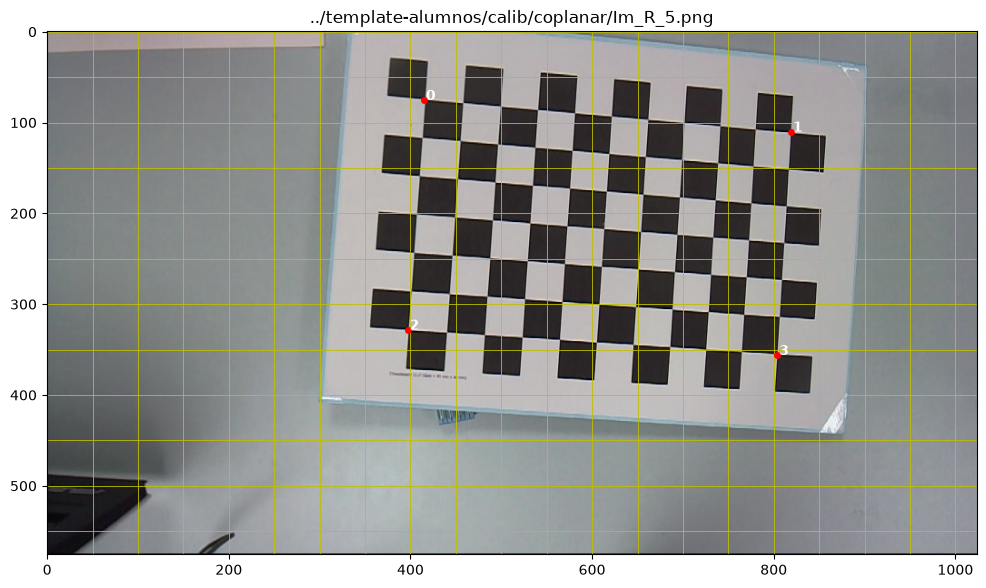

In [31]:
k = 5 # La vista k

filename = f'{filepath_base}/Im_R_{k}.png'
rgb = cv2.imread(filename)

plt.figure(figsize=(12,8), dpi=100)
plt.imshow(rgb)
grilla(rgb)
plt.title(filename)

esq_sup_izq = (415,75)
esq_sup_der = (819,110)
esq_inf_izq = (397,328)
esq_inf_der = (804,356)

plt.plot(esq_sup_izq[0], esq_sup_izq[1],'ro', markersize=4)
plt.plot(esq_sup_der[0], esq_sup_der[1],'ro', markersize=4)  
plt.plot(esq_inf_izq[0], esq_inf_izq[1],'ro', markersize=4)  
plt.plot(esq_inf_der[0], esq_inf_der[1],'ro', markersize=4)  


# (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
plt.text(esq_sup_izq[0] + 2, esq_sup_izq[1], str(0), color='white', fontsize=10, weight='bold')
plt.text(esq_sup_der[0] + 2, esq_sup_der[1], str(1), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_izq[0] + 2, esq_inf_izq[1], str(2), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_der[0] + 2, esq_inf_der[1], str(3), color='white', fontsize=10, weight='bold')

plt.show()

# [*esq_sup_izq, *esq_sup_der] -> aplana las tuplas para tener [u0, v0, u1, v1] en lugar de [(u0,v0), (u1,v1)]
imgPtsList[k-1] = np.array([*esq_sup_izq, *esq_sup_der, *esq_inf_izq, *esq_inf_der])

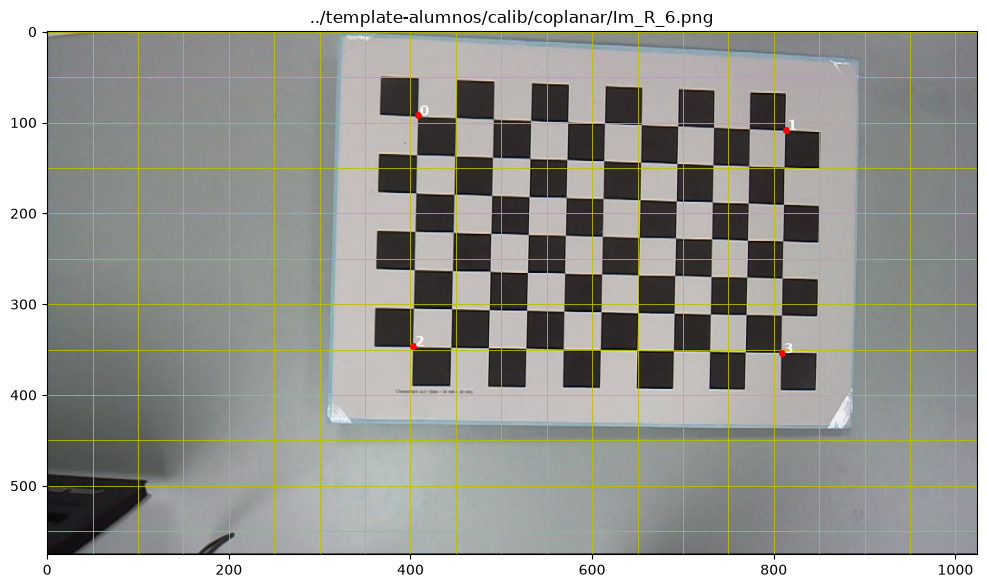

In [32]:
k = 6 # La vista k

filename = f'{filepath_base}/Im_R_{k}.png'
rgb = cv2.imread(filename)

plt.figure(figsize=(12,8), dpi=100)
plt.imshow(rgb)
grilla(rgb)
plt.title(filename)

esq_sup_izq = (408,92)
esq_sup_der = (813,108)
esq_inf_izq = (403,346)
esq_inf_der = (809,354)

plt.plot(esq_sup_izq[0], esq_sup_izq[1],'ro', markersize=4)
plt.plot(esq_sup_der[0], esq_sup_der[1],'ro', markersize=4)  
plt.plot(esq_inf_izq[0], esq_inf_izq[1],'ro', markersize=4)  
plt.plot(esq_inf_der[0], esq_inf_der[1],'ro', markersize=4)  


# (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
plt.text(esq_sup_izq[0] + 2, esq_sup_izq[1], str(0), color='white', fontsize=10, weight='bold')
plt.text(esq_sup_der[0] + 2, esq_sup_der[1], str(1), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_izq[0] + 2, esq_inf_izq[1], str(2), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_der[0] + 2, esq_inf_der[1], str(3), color='white', fontsize=10, weight='bold')

plt.show()

# [*esq_sup_izq, *esq_sup_der] -> aplana las tuplas para tener [u0, v0, u1, v1] en lugar de [(u0,v0), (u1,v1)]
imgPtsList[k-1] = np.array([*esq_sup_izq, *esq_sup_der, *esq_inf_izq, *esq_inf_der])

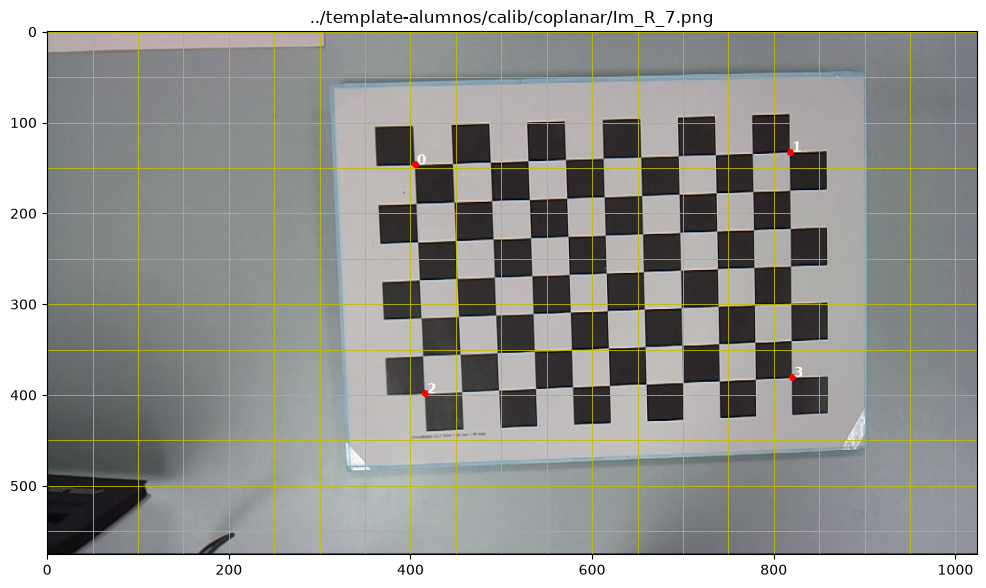

In [33]:
k = 7 # La vista k

filename = f'{filepath_base}/Im_R_{k}.png'
rgb = cv2.imread(filename)

plt.figure(figsize=(12,8), dpi=100)
plt.imshow(rgb)
grilla(rgb)
plt.title(filename)

esq_sup_izq = (405,146)
esq_sup_der = (818,132)
esq_inf_izq = (416,398)
esq_inf_der = (820,380)

plt.plot(esq_sup_izq[0], esq_sup_izq[1],'ro', markersize=4)
plt.plot(esq_sup_der[0], esq_sup_der[1],'ro', markersize=4)  
plt.plot(esq_inf_izq[0], esq_inf_izq[1],'ro', markersize=4)  
plt.plot(esq_inf_der[0], esq_inf_der[1],'ro', markersize=4)  


# (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
plt.text(esq_sup_izq[0] + 2, esq_sup_izq[1], str(0), color='white', fontsize=10, weight='bold')
plt.text(esq_sup_der[0] + 2, esq_sup_der[1], str(1), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_izq[0] + 2, esq_inf_izq[1], str(2), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_der[0] + 2, esq_inf_der[1], str(3), color='white', fontsize=10, weight='bold')

plt.show()

# [*esq_sup_izq, *esq_sup_der] -> aplana las tuplas para tener [u0, v0, u1, v1] en lugar de [(u0,v0), (u1,v1)]
imgPtsList[k-1] = np.array([*esq_sup_izq, *esq_sup_der, *esq_inf_izq, *esq_inf_der])

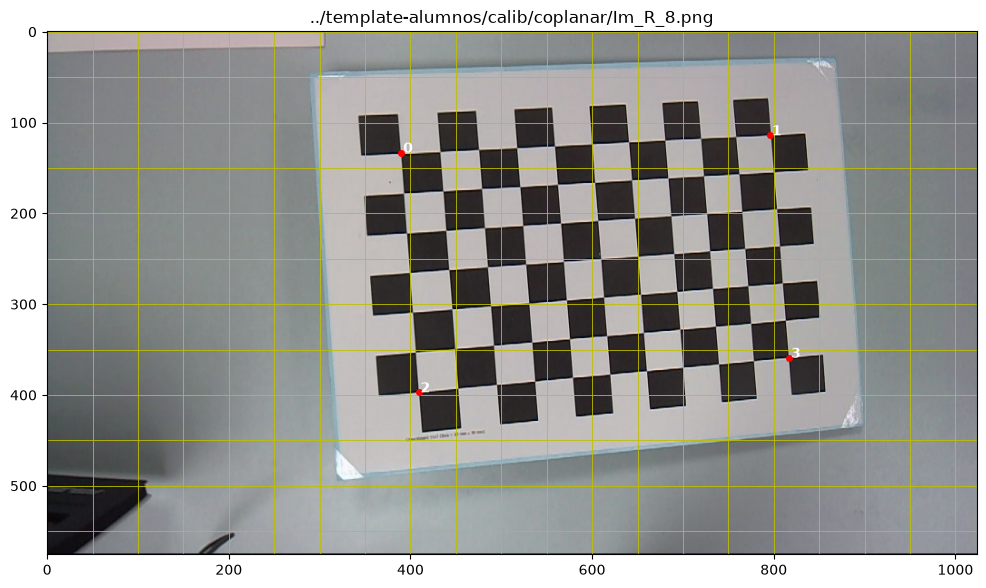

In [34]:
k = 8 # La vista k

filename = f'{filepath_base}/Im_R_{k}.png'
rgb = cv2.imread(filename)

plt.figure(figsize=(12,8), dpi=100)
plt.imshow(rgb)
grilla(rgb)
plt.title(filename)

esq_sup_izq = (390,133)
esq_sup_der = (796,114)
esq_inf_izq = (409,397)
esq_inf_der = (817,359)

plt.plot(esq_sup_izq[0], esq_sup_izq[1],'ro', markersize=4)
plt.plot(esq_sup_der[0], esq_sup_der[1],'ro', markersize=4)  
plt.plot(esq_inf_izq[0], esq_inf_izq[1],'ro', markersize=4)  
plt.plot(esq_inf_der[0], esq_inf_der[1],'ro', markersize=4)  


# (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
plt.text(esq_sup_izq[0] + 2, esq_sup_izq[1], str(0), color='white', fontsize=10, weight='bold')
plt.text(esq_sup_der[0] + 2, esq_sup_der[1], str(1), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_izq[0] + 2, esq_inf_izq[1], str(2), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_der[0] + 2, esq_inf_der[1], str(3), color='white', fontsize=10, weight='bold')

plt.show()

# [*esq_sup_izq, *esq_sup_der] -> aplana las tuplas para tener [u0, v0, u1, v1] en lugar de [(u0,v0), (u1,v1)]
imgPtsList[k-1] = np.array([*esq_sup_izq, *esq_sup_der, *esq_inf_izq, *esq_inf_der])

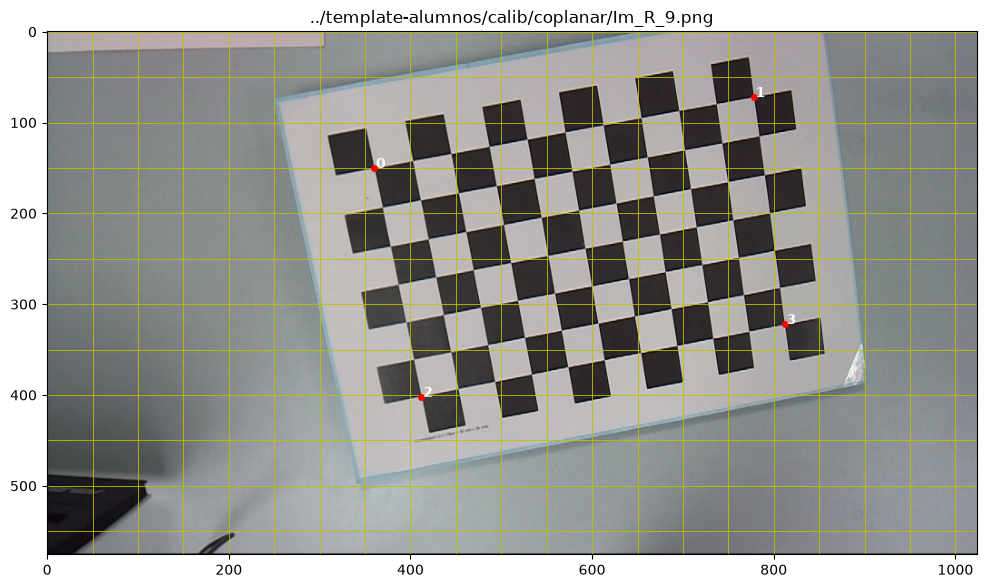

In [35]:
k = 9 # La vista k

filename = f'{filepath_base}/Im_R_{k}.png'
rgb = cv2.imread(filename)

plt.figure(figsize=(12,8), dpi=100)
plt.imshow(rgb)
grilla(rgb)
plt.title(filename)

esq_sup_izq = (360,150)
esq_sup_der = (778,72)
esq_inf_izq = (412,402)
esq_inf_der = (812,322)

plt.plot(esq_sup_izq[0], esq_sup_izq[1],'ro', markersize=4)
plt.plot(esq_sup_der[0], esq_sup_der[1],'ro', markersize=4)  
plt.plot(esq_inf_izq[0], esq_inf_izq[1],'ro', markersize=4)  
plt.plot(esq_inf_der[0], esq_inf_der[1],'ro', markersize=4)  


# (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
plt.text(esq_sup_izq[0] + 2, esq_sup_izq[1], str(0), color='white', fontsize=10, weight='bold')
plt.text(esq_sup_der[0] + 2, esq_sup_der[1], str(1), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_izq[0] + 2, esq_inf_izq[1], str(2), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_der[0] + 2, esq_inf_der[1], str(3), color='white', fontsize=10, weight='bold')

plt.show()

# [*esq_sup_izq, *esq_sup_der] -> aplana las tuplas para tener [u0, v0, u1, v1] en lugar de [(u0,v0), (u1,v1)]
imgPtsList[k-1] = np.array([*esq_sup_izq, *esq_sup_der, *esq_inf_izq, *esq_inf_der])

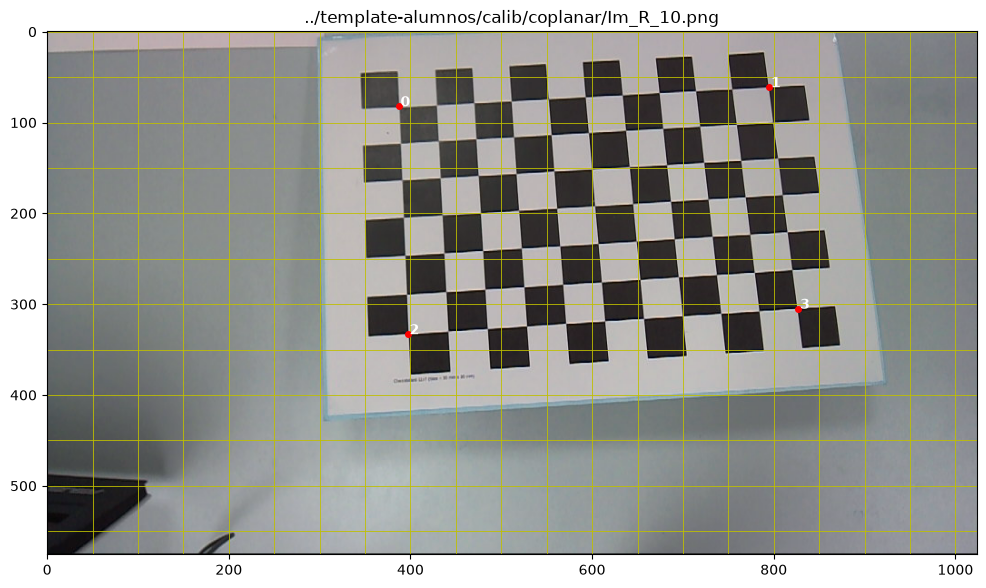

In [36]:
k = 10 # La vista k

filename = f'{filepath_base}/Im_R_{k}.png'
rgb = cv2.imread(filename)

plt.figure(figsize=(12,8), dpi=100)
plt.imshow(rgb)
grilla(rgb)
plt.title(filename)

esq_sup_izq = (387,82)
esq_sup_der = (795,61)
esq_inf_izq = (397,333)
esq_inf_der = (827,305)

plt.plot(esq_sup_izq[0], esq_sup_izq[1],'ro', markersize=4)
plt.plot(esq_sup_der[0], esq_sup_der[1],'ro', markersize=4)  
plt.plot(esq_inf_izq[0], esq_inf_izq[1],'ro', markersize=4)  
plt.plot(esq_inf_der[0], esq_inf_der[1],'ro', markersize=4)  


# (x, y, texto) con un pequeño desfase (+2) para que el texto no tape el círculo
plt.text(esq_sup_izq[0] + 2, esq_sup_izq[1], str(0), color='white', fontsize=10, weight='bold')
plt.text(esq_sup_der[0] + 2, esq_sup_der[1], str(1), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_izq[0] + 2, esq_inf_izq[1], str(2), color='white', fontsize=10, weight='bold')
plt.text(esq_inf_der[0] + 2, esq_inf_der[1], str(3), color='white', fontsize=10, weight='bold')

plt.show()

# [*esq_sup_izq, *esq_sup_der] -> aplana las tuplas para tener [u0, v0, u1, v1] en lugar de [(u0,v0), (u1,v1)]
imgPtsList[k-1] = np.array([*esq_sup_izq, *esq_sup_der, *esq_inf_izq, *esq_inf_der])

In [37]:
objPts

array([[  0,   0],
       [300,   0],
       [  0, 180],
       [300, 180]])

In [38]:
np.savetxt(f'{filepath_base}/p_corners.txt', np.array(objPts), fmt='%d') # fmt='%d' escribe enteros, si no escribe con 3.72000...e+02

In [39]:
imgPtsList

[array([372, 104, 774, 112, 369, 351, 772, 356]),
 array([384, 175, 778,  84, 441, 415, 832, 323]),
 array([384, 135, 793, 115, 399, 389, 807, 363]),
 array([405, 114, 817, 109, 410, 367, 816, 357]),
 array([415,  75, 819, 110, 397, 328, 804, 356]),
 array([408,  92, 813, 108, 403, 346, 809, 354]),
 array([405, 146, 818, 132, 416, 398, 820, 380]),
 array([390, 133, 796, 114, 409, 397, 817, 359]),
 array([360, 150, 778,  72, 412, 402, 812, 322]),
 array([387,  82, 795,  61, 397, 333, 827, 305])]

In [40]:
np.savetxt(f'{filepath_base}/detected_corners.txt', np.array(imgPtsList), fmt='%d') # fmt='%d' escribe enteros, si no escribe con 3.72000...e+02